In [1]:

import pandas as pd
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())


Saving archive (8).zip to archive (8) (1).zip
Dataset shape: (7043, 21)

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Missing values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

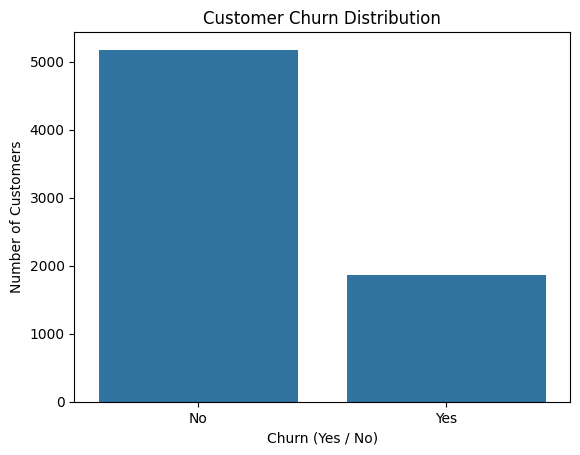

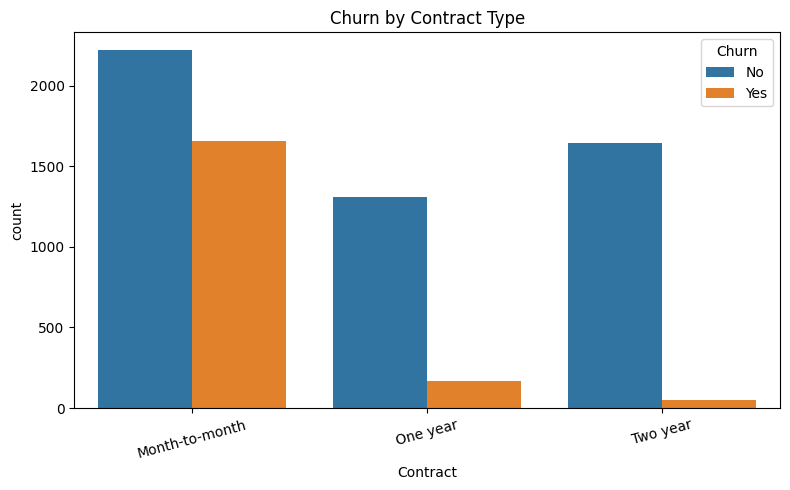

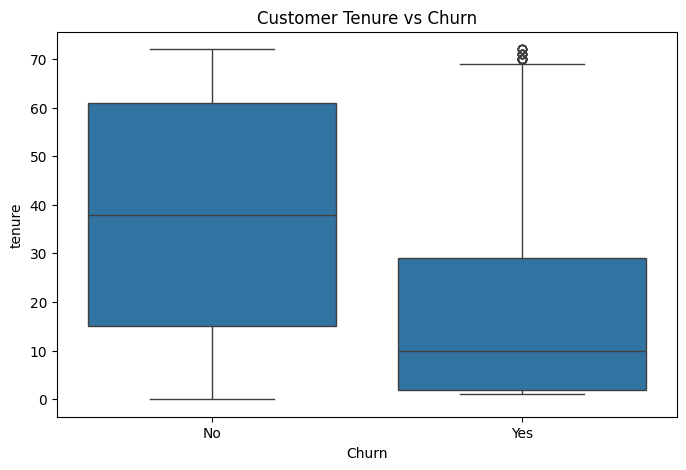

In [2]:



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nChurn counts:")
print(df["Churn"].value_counts())

print("\nChurn percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)


sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (Yes / No)")
plt.ylabel("Number of Customers")
plt.show()

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Customer Tenure vs Churn")
plt.show()


In [3]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


data = df.copy()

data = data.drop(columns=["customerID"])


data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)


X = data.drop(columns=["Churn"])
y = data["Churn"].map({"No": 0, "Yes": 1})


numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()


numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training rows:", X_train_processed.shape[0])
print("Testing rows:", X_test_processed.shape[0])
print("Features after encoding:", X_train_processed.shape[1])
print("Missing target values:", y.isna().sum())
print("Preprocessing complete!")


Training rows: 5634
Testing rows: 1409
Features after encoding: 45
Missing target values: 0
Preprocessing complete!


In [4]:



from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)
from sklearn.base import clone
from xgboost import XGBClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "SVM": SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    print("Training:", name)
    model.fit(X_train_processed, y_train)

    predictions = model.predict(X_test_processed)
    probabilities = model.predict_proba(X_test_processed)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = model

results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC", ascending=False
)

display(results_df.round(3))


Training: Logistic Regression
Training: Random Forest
Training: SVM
Training: XGBoost


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,XGBoost,0.806,0.667,0.535,0.593,0.844
0,Logistic Regression,0.738,0.504,0.783,0.614,0.841
1,Random Forest,0.783,0.618,0.476,0.538,0.822
2,SVM,0.744,0.512,0.773,0.616,0.821


In [5]:

!pip -q install shap


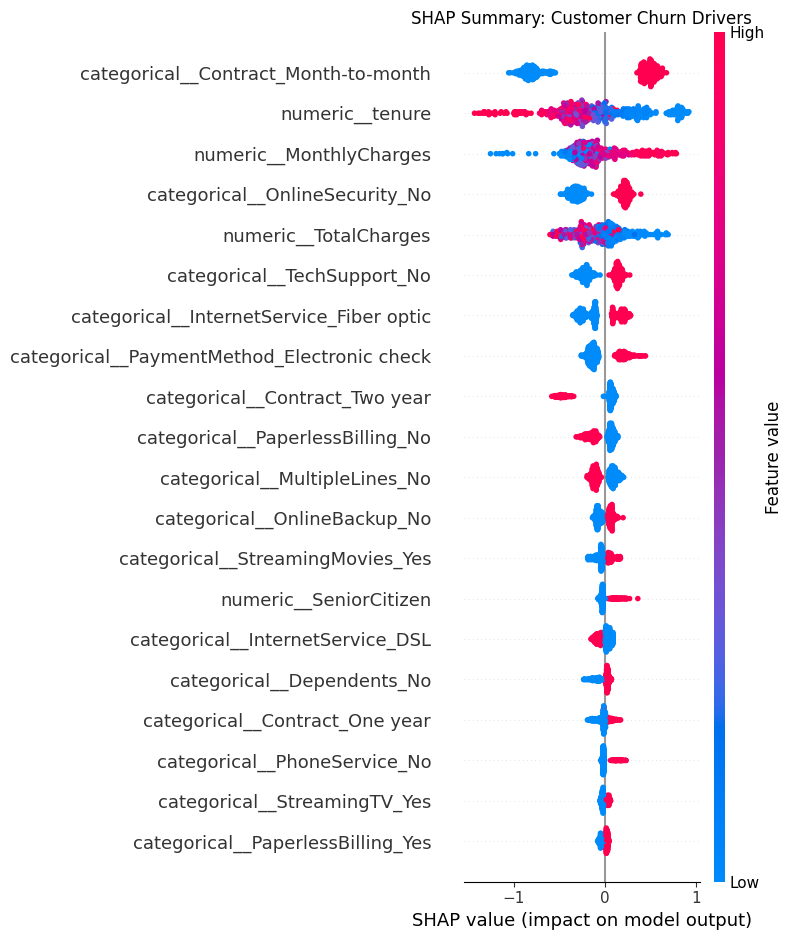

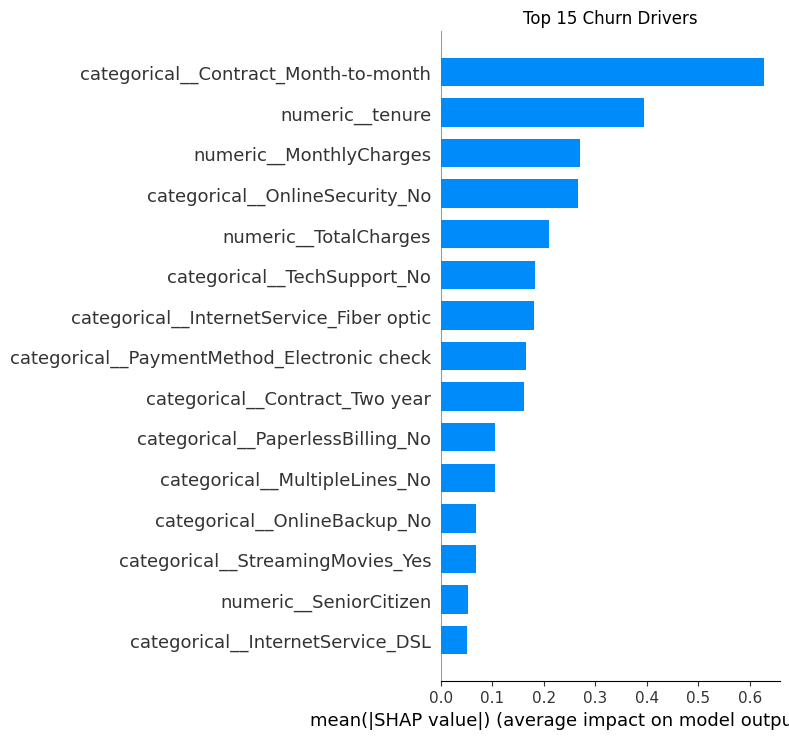

In [6]:

import shap
import numpy as np
import matplotlib.pyplot as plt


best_model = trained_models["XGBoost"]


feature_names = preprocessor.get_feature_names_out()

X_shap = pd.DataFrame(
    X_train_processed[:500].toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed[:500],
    columns=feature_names
)


explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_shap)

shap.summary_plot(shap_values, X_shap, show=False)
plt.title("SHAP Summary: Customer Churn Drivers")
plt.tight_layout()
plt.show()


shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    max_display=15,
    show=False
)
plt.title("Top 15 Churn Drivers")
plt.tight_layout()
plt.show()


In [7]:



best_model = trained_models["XGBoost"]


X_all_processed = preprocessor.transform(X)

churn_probability = best_model.predict_proba(
    X_all_processed
)[:, 1]


powerbi_df = df.copy()

powerbi_df["ChurnProbability"] = churn_probability

powerbi_df["PredictedChurn"] = (
    churn_probability >= 0.5
).astype(int)

powerbi_df["RiskLevel"] = pd.cut(
    churn_probability,
    bins=[-0.001, 0.30, 0.60, 1.0],
    labels=["Low", "Medium", "High"]
)


powerbi_df.to_csv(
    "telecom_churn_powerbi.csv", index=False
)

results_df.to_csv(
    "model_comparison.csv", index=False
)

print("Both files created successfully!")
print(powerbi_df.head())


from google.colab import files

files.download("telecom_churn_powerbi.csv")
files.download("model_comparison.csv")


Both files created successfully!
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... StreamingMovies  \
0  No phone service             DSL             No  ...              No   
1                No             DSL            Yes  ...              No   
2                No             DSL            Yes  ...              No   
3  No phone service             DSL            Yes  ...              No   
4                No     Fiber optic             No  ...              No   

         Contract PaperlessBilling 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
print("Variables currently loaded:")
%whos

Variables currently loaded:
Variable   Type          Data/Info
----------------------------------
conn       Connection    <sqlite3.Connection object at 0x7fc0beb38220>
pd         module        <module 'pandas' from '/u<...>ages/pandas/__init__.py'>
sqlite3    module        <module 'sqlite3' from '/<...>.13/sqlite3/__init__.py'>


In [4]:
from google.colab import files

uploaded = files.upload()

Saving archive (8).zip to archive (8).zip


In [5]:
import zipfile
import os

zip_path = "archive (8).zip"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall("churn_data")

for root, dirs, files in os.walk("churn_data"):
    for file in files:
        print(os.path.join(root, file))

churn_data/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [6]:
import pandas as pd

df = pd.read_csv(
    "churn_data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
import sqlite3
import pandas as pd

conn = sqlite3.connect(":memory:")


df.to_sql("customers", conn, if_exists="replace", index=False)

print("SQL table created successfully!")

SQL table created successfully!


In [8]:
query = """
SELECT
    Churn,
    COUNT(*) AS customer_count
FROM customers
GROUP BY Churn;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Churn,customer_count
0,No,5174
1,Yes,1869


In [10]:
query = """
SELECT Churn, COUNT(*) AS customers
FROM customers
GROUP BY Churn;
"""

result = pd.read_sql_query(query, conn)

total = result["customers"].sum()
churned = result[result["Churn"] == "Yes"]["customers"].values[0]

print("Total customers:", total)
print("Churned customers:", churned)
print("Churn rate:", round(churned / total * 100, 2), "%")

Total customers: 7043
Churned customers: 1869
Churn rate: 26.54 %


In [11]:
query = """
SELECT Contract, COUNT(*) AS churned_customers
FROM customers
WHERE Churn = 'Yes'
GROUP BY Contract
ORDER BY churned_customers DESC;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Contract,churned_customers
0,Month-to-month,1655
1,One year,166
2,Two year,48


In [12]:
query = """
SELECT Contract,
       COUNT(*) AS total_customers,
       SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned,
       ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
       / COUNT(*), 2) AS churn_rate
FROM customers
GROUP BY Contract;
"""

result = pd.read_sql_query(query, conn)
display(result)

,Contract,total_customers,churned,churn_rate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


In [13]:
query = """
SELECT InternetService,
       COUNT(*) AS total_customers,
       SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned
FROM customers
GROUP BY InternetService;
"""

result = pd.read_sql_query(query, conn)
display(result)

,InternetService,total_customers,churned
0,DSL,2421,459
1,Fiber optic,3096,1297
2,No,1526,113


In [14]:
query = """
SELECT InternetService,
       COUNT(*) AS total_customers,
       SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned,
       ROUND(
           100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
           / COUNT(*), 2
       ) AS churn_rate
FROM customers
GROUP BY InternetService;
"""

result = pd.read_sql_query(query, conn)
display(result)

,InternetService,total_customers,churned,churn_rate
0,DSL,2421,459,18.96
1,Fiber optic,3096,1297,41.89
2,No,1526,113,7.40


In [15]:
query = """
SELECT PaymentMethod,
       COUNT(*) AS total_customers,
       SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned
FROM customers
GROUP BY PaymentMethod;
"""

result = pd.read_sql_query(query, conn)
display(result)

,PaymentMethod,total_customers,churned
0,Bank transfer (automatic),1544,258
1,Credit card (automatic),1522,232
2,Electronic check,2365,1071
3,Mailed check,1612,308


In [16]:
query = """
SELECT PaymentMethod,
       COUNT(*) AS total_customers,
       SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned,
       ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
       / COUNT(*), 2) AS churn_rate
FROM customers
GROUP BY PaymentMethod;
"""

result = pd.read_sql_query(query, conn)
display(result)

,PaymentMethod,total_customers,churned,churn_rate
0,Bank transfer (automatic),1544,258,16.71
1,Credit card (automatic),1522,232,15.24
2,Electronic check,2365,1071,45.29
3,Mailed check,1612,308,19.11


In [17]:
query = """
SELECT
    CASE
        WHEN tenure <= 12 THEN '0-12 months'
        WHEN tenure <= 24 THEN '13-24 months'
        ELSE 'Above 24 months'
    END AS tenure_group,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned
FROM customers
GROUP BY tenure_group;
"""

result = pd.read_sql_query(query, conn)
display(result)

,tenure_group,total_customers,churned
0,0-12 months,2186,1037
1,13-24 months,1024,294
2,Above 24 months,3833,538


In [18]:
query = """
SELECT
    CASE
        WHEN tenure <= 12 THEN '0-12 months'
        WHEN tenure <= 24 THEN '13-24 months'
        ELSE 'Above 24 months'
    END AS tenure_group,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS churn_rate
FROM customers
GROUP BY tenure_group;
"""

result = pd.read_sql_query(query, conn)
display(result)

,tenure_group,total_customers,churned,churn_rate
0,0-12 months,2186,1037,47.44
1,13-24 months,1024,294,28.71
2,Above 24 months,3833,538,14.04


In [19]:
print(df.shape)
print(df.columns.tolist())
print(df["Churn"].value_counts())

(7043, 21)
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [20]:

df_ml = df.drop("customerID", axis=1)


df_ml["Churn"] = df_ml["Churn"].map({"No": 0, "Yes": 1})


X = df_ml.drop("Churn", axis=1)
y = df_ml["Churn"]

print("Input data shape:", X.shape)
print("Target data shape:", y.shape)

Input data shape: (7043, 19)
Target data shape: (7043,)


In [21]:
X = pd.get_dummies(X, drop_first=True)

print("Data ready for ML!")
print("Number of input columns:", X.shape[1])
print(X.head())

Data ready for ML!
Number of input columns: 6559
   SeniorCitizen  tenure  MonthlyCharges  gender_Male  Partner_Yes  \
0              0       1           29.85        False         True   
1              0      34           56.95         True        False   
2              0       2           53.85         True        False   
3              0      45           42.30         True        False   
4              0       2           70.70        False        False   

   Dependents_Yes  PhoneService_Yes  MultipleLines_No phone service  \
0           False             False                            True   
1           False              True                           False   
2           False              True                           False   
3           False             False                            True   
4           False              True                           False   

   MultipleLines_Yes  InternetService_Fiber optic  ...  TotalCharges_995.35  \
0              False    

In [22]:
print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [23]:

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)


df = df.dropna(subset=["TotalCharges"])

print(df.shape)
print(df["TotalCharges"].dtype)

(7032, 21)
float64


In [24]:

df_ml = df.drop("customerID", axis=1)


df_ml["Churn"] = df_ml["Churn"].map({"No": 0, "Yes": 1})


X = df_ml.drop("Churn", axis=1)
y = df_ml["Churn"]


X = pd.get_dummies(X, drop_first=True)

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (7032, 30)
Target shape: (7032,)


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 5625
Testing rows: 1407


In [26]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [27]:
from sklearn.metrics import accuracy_score


y_pred = model.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 80.31 %


In [28]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [29]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[916 117]
 [160 214]]


In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_pred) * 100, 2), "%")

Random Forest Accuracy: 78.96 %


In [31]:
from sklearn.metrics import classification_report

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.63      0.52      0.57       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [32]:
!pip -q install xgboost

In [33]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score

model_xgb = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    eval_metric="logloss",
    random_state=42
)

model_xgb.fit(X_train, y_train)

xgb_pred = model_xgb.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, xgb_pred) * 100, 2), "%")
print(classification_report(y_test, xgb_pred))

Accuracy: 79.53 %
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.64      0.53      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407



In [34]:
import pandas as pd

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model_xgb.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

print(importance.head(10))

                           Feature  Importance
10     InternetService_Fiber optic    0.197150
25               Contract_Two year    0.197105
24               Contract_One year    0.186823
11              InternetService_No    0.078498
1                           tenure    0.065074
28  PaymentMethod_Electronic check    0.046343
23             StreamingMovies_Yes    0.031468
13              OnlineSecurity_Yes    0.026183
26            PaperlessBilling_Yes    0.025557
21                 StreamingTV_Yes    0.020811


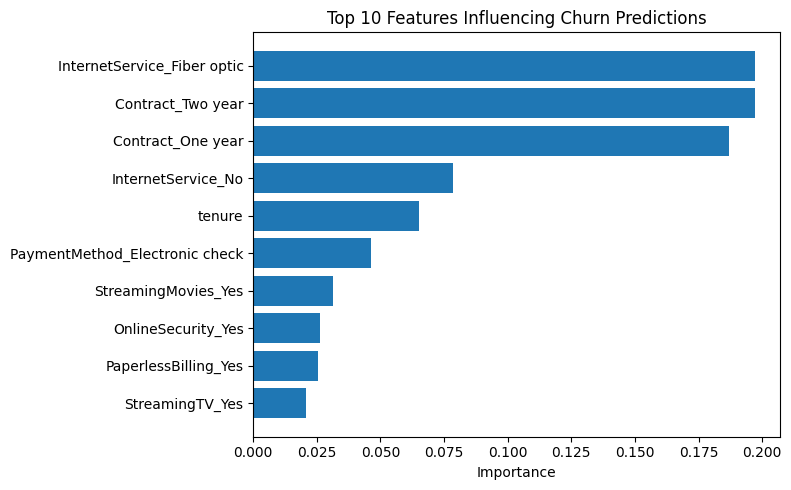

In [35]:
import matplotlib.pyplot as plt

top_features = importance.head(10).sort_values("Importance")

plt.figure(figsize=(8, 5))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.title("Top 10 Features Influencing Churn Predictions")
plt.tight_layout()
plt.show()

In [36]:
from sklearn.metrics import accuracy_score, f1_score, recall_score

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost"],
    "Accuracy (%)": [
        accuracy_score(y_test, y_pred) * 100,
        accuracy_score(y_test, rf_pred) * 100,
        accuracy_score(y_test, xgb_pred) * 100
    ],
    "Churn Recall (%)": [
        recall_score(y_test, y_pred) * 100,
        recall_score(y_test, rf_pred) * 100,
        recall_score(y_test, xgb_pred) * 100
    ],
    "Churn F1-Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, xgb_pred)
    ]
})

print(results.round(2))

                 Model  Accuracy (%)  Churn Recall (%)  Churn F1-Score
0  Logistic Regression         80.31             57.22            0.61
1        Random Forest         78.96             51.87            0.57
2              XGBoost         79.53             53.48            0.58


In [37]:
import pandas as pd

importance_lr = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.coef_[0]
})

importance_lr["Absolute_Importance"] = importance_lr["Importance"].abs()

importance_lr = importance_lr.sort_values(
    by="Absolute_Importance", ascending=False
)

print(importance_lr[["Feature", "Importance"]].head(10))

                           Feature  Importance
25               Contract_Two year   -1.356417
24               Contract_One year   -0.748452
10     InternetService_Fiber optic    0.689165
13              OnlineSecurity_Yes   -0.459153
7                 PhoneService_Yes   -0.426528
19                 TechSupport_Yes   -0.419646
28  PaymentMethod_Electronic check    0.393234
26            PaperlessBilling_Yes    0.299733
9                MultipleLines_Yes    0.280302
8   MultipleLines_No phone service    0.254493


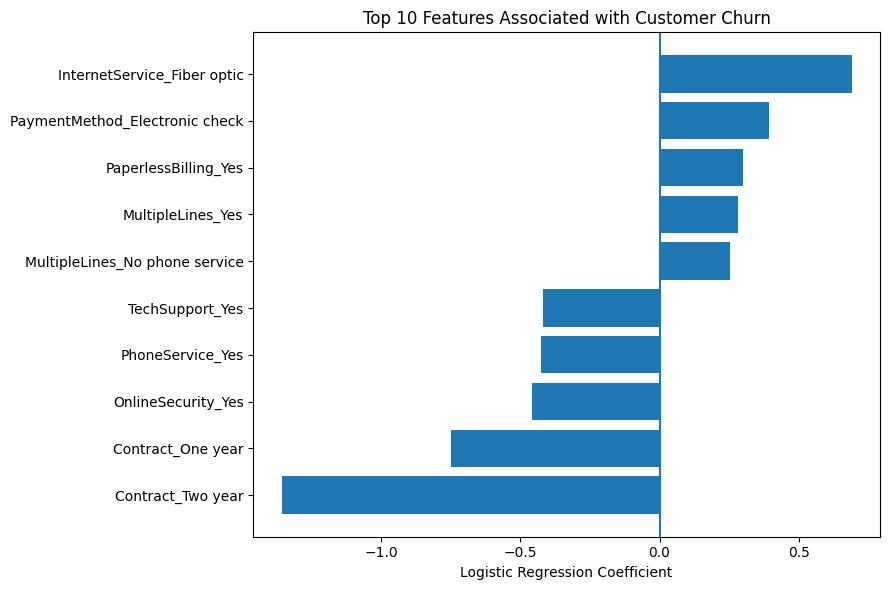

In [38]:
import matplotlib.pyplot as plt

top10 = importance_lr.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top10["Feature"], top10["Importance"])
plt.axvline(0)
plt.xlabel("Logistic Regression Coefficient")
plt.title("Top 10 Features Associated with Customer Churn")
plt.tight_layout()
plt.show()

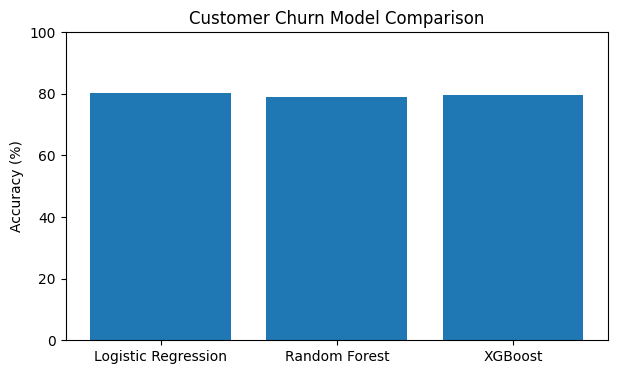

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.bar(results["Model"], results["Accuracy (%)"])
plt.ylabel("Accuracy (%)")
plt.title("Customer Churn Model Comparison")
plt.ylim(0, 100)
plt.show()